## **一、第四周要解决什么问题**

第三周已经说明“图像可以压成潜变量，Transformer 可以处理这些潜变量”。但固定一张带噪图拟合成功，还没有回答：**每次换图、换时间、换噪声之后，网络能否学到共同规律？从纯噪声出发的一千次更新，是否真的能够走到可解码的图标分布？**

本周建立一条可追溯的无条件潜空间扩散训练链：数据 → 冻结空间 VAE → 缓存 → 随机加噪 → DiT 预测噪声 → 优化与 EMA → 完整反向链 → 冻结解码器 → 结果分析。我们同时学习怎样区分算法正确、工程能运行、验证损失降低和生成质量成立。

本笔记是 **教学实验**：使用你已通过验收的项目 DDPM；DiT 明确复用第三周 Notebook 的唯一教学实现，不代写 `src/minigen/models/dit_block.py`。个人 VAE、DiT 作业及理解验收保留待做。不做文本、CFG、Flow，也不将短训样本称作开放域生成能力。

### **1. 学习顺序与成果边界**

| 你要回答的问题 | 本周证据 | 不能由此推出 |
| --- | --- | --- |
| 数据和编码约定一致吗？ | 完整 train/validation 缓存、身份与哈希 | 任何 VAE 都能直接换用 |
| 随机监督真的在更新模型吗？ | 固定监督与随机监督分开，独立验证探针 | 损失下降等于图标生成良好 |
| 恢复能否接着同一训练继续？ | 日程/数据/模型身份检查、相同 CPU 数据顺序对照 | 跨设备逐位一致 |
| 采样是否抵达终点？ | 完整 1000 次求值及完成标记 | 把中间态当最终样本 |
| 生成有什么局限？ | 全部固定种子图、轨迹、解析诊断与最近邻 | 无条件模型能遵循描述 |

本周阅读主线为 LDM 的压缩与潜空间目标、DiT 的架构和训练；DDPM 复习采样算法。DDIM 是解释加速方法的选读，本次仍执行完整 DDPM 链。论文见 [papers](../papers/README.md)。

In [1]:
import hashlib
import json
import math
import os
import platform
import sys
import time
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").exists() and (p / "src/minigen").is_dir()
)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from PIL import Image

from minigen.autoencoders.frozen import FrozenVAE, hash_file, to_image
from minigen.data.icons import load_manifest
from minigen.evaluation.icons import parse_icons
from minigen.objectives.ddpm_scheduler import DDPMScheduler
from minigen.samplers.ddpm_loop import sample_ddpm
from minigen.training.denoising import TrainConfig, seed_all

torch.set_num_threads(4)
SEED = 20261030
seed_all(SEED)
RUN = ROOT / "artifacts/runs/s2_week4"
FIG = ROOT / "reports/stage2/figures/week4"
RUN.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
DEVICE = "cpu"
if torch.backends.mps.is_available():
    try:
        probe = torch.ones(4, device="mps", requires_grad=True)
        probe.square().sum().backward()
        torch.mps.synchronize()
        DEVICE = "mps"
    except RuntimeError as error:
        print("MPS 小案例失败，使用 CPU：", error)
print(
    {
        "root": str(ROOT),
        "python": sys.version.split()[0],
        "interpreter": sys.executable,
        "torch": torch.__version__,
        "device": DEVICE,
        "machine": platform.machine(),
    }
)

{'root': '/Users/lucius/projects/personal/MiniGen', 'python': '3.12.14', 'interpreter': '/Users/lucius/projects/personal/MiniGen/.venv/bin/python', 'torch': '2.14.1', 'device': 'mps', 'machine': 'arm64'}


## **二、先把训练与推理的整体信息流放在一起**

### **1. 哪些模块负责压缩，哪些模块负责生成**

设原图 $x\in[-1,1]^{3\times128\times128}$。冻结编码器给出后验 $q_\phi(h\mid x)$，本项目固定取均值 $m_\phi(x)$，再乘模型配置的缩放 $s=0.13025$，得到 $z_0=s m_\phi(x)\in\mathbb R^{4\times16\times16}$。

训练流：真实图 $x$ → 后验均值 → 缩放后的 $z_0$ → 按随机时间加噪得到 $z_t$ → 时间条件 DiT → 预测 $\epsilon_\theta$ → 与加噪用的 $\epsilon$ 比较。只有 DiT 更新参数；冻结 VAE 不参加优化。

推理流：标准正态 $z_T$ → DiT 预测与采样器反复更新 → 估计的 $z_0$ → 除以 $s$ → 冻结解码器 → RGB。**推理没有真实 $x$、没有真实 $z_0$，也不知道训练时加过的噪声。**

| 位置 | 张量 | 角色 |
| --- | --- | --- |
| 图像 | `[b,3,128,128]` | 像素输入或解码输出 |
| 潜变量 | `[b,4,16,16]` | 编码后生成模型负责的空间 |
| patch token | `[b,64,16]` | patch=2，每块 2×2×4=16 个数 |
| Transformer 隐藏特征 | `[b,64,d]` | d=128（教学短训）或 256（主规格） |
| 噪声预测 | `[b,4,16,16]` | 与潜变量同形，含义是标准噪声 |

压缩前后每张元素数从 49152 到 1024，相差 48 倍；这不是保留信息量的证明，也不是实际耗时必然降低 48 倍。注意力、投影、VAE 编解码和设备开销仍需要实测。

### **2. 为什么缓存固定均值而不每轮重新采样后验**

若后验是对角高斯，可写 $h=m_\phi(x)+\sigma_\phi(x)\odot\eta$，$\eta\sim\mathcal N(0,I)$。缓存均值相当于固定了编码策略，避免每个 epoch 引入额外的后验噪声，便于有限预算下复现实验；它不等同于原 LDM 所有训练设置。

扩散噪声 $\epsilon$ 与 VAE 的后验噪声 $\eta$ 是两种不同随机量。本周固定均值缓存之后，仍会每步重新采样扩散噪声。不能把“编码缓存固定”误解为“训练噪声也固定”。

> 缩放例子：若未缩放编码值为 2，则 $z_0=2\times0.13025=0.2605$。解码时输入 $0.2605/0.13025=2$。若遗漏除法，解码器实际接收 0.2605，已经不再是编码器输出的数值空间。对潜变量再做临时标准化也会改变整个训练与解码约定。

In [2]:
s = 0.13025
h = torch.tensor([2.0, -1.0, 0.5])
z = s * h
assert torch.allclose(z / s, h)
print({"h": h.tolist(), "scaled_z": z.tolist(), "recovered": (z / s).tolist()})

{'h': [2.0, -1.0, 0.5], 'scaled_z': [0.2605000138282776, -0.1302500069141388, 0.0651250034570694], 'recovered': [2.0, -1.0, 0.5]}


## **三、数据缓存是一份有身份的实验输入**

### **1. 本周使用哪些数据，为什么不碰测试集**

沿用第三周冻结的数据版本：10000 张训练，1000 张验证；组合外、模板外和分布内测试均不用于本次调参。所有图片尺寸 128、白底 RGB，颜色、形状、数量和空间关系来自确定性场景属性。

缓存需要同时约束图像次序、图片哈希、完整清单哈希、VAE revision、权重哈希、均值策略、预处理、缩放和 dtype。相同文件名不表示内容相同。分片可以减少中断损失：完成一个分片就写身份与载荷哈希；索引只有标为 complete 且所有样本齐全时，才能称“完整缓存”。

分片目录是本地实验产物，不纳入 Git；仓库保留配置、索引结构说明和质量证据。复用缓存前依然核对身份，不能因为路径存在就跳过验证。

In [3]:
manifest = ROOT / "data/manifests/synthetic_icons_week3_v1.jsonl"
records = load_manifest(manifest, ROOT / "data", verify_hashes=True)
train_rows = [r for r in records if r["split"] == "train"]
val_rows = [r for r in records if r["split"] == "validation"]
assert len(train_rows) == 10000 and len(val_rows) == 1000
assert not ({r["group_id"] for r in train_rows} & {r["group_id"] for r in val_rows})
print(
    {
        "manifest_sha256": hash_file(manifest),
        "train": len(train_rows),
        "validation": len(val_rows),
        "test_used": False,
        "latent_payload_MiB": 11000 * 4 * 16 * 16 * 4 / 2**20,
    }
)

{'manifest_sha256': '4ab52fc580d9a5bf9b315a1c2449ab78a20cabcfb18a0d50631990b63b7371e4', 'train': 10000, 'validation': 1000, 'test_used': False, 'latent_payload_MiB': 42.96875}


### **2. 显式加载冻结 VAE 并建立全量缓存**

以下单元是明确的本地计算入口：从这里开始将缓存、训练与采样合计限制为 30 分钟，安装与论文下载不计入。只读取已存在的固定 VAE 文件，不在 Notebook 自动下载模型。若超时，保留已完成分片并说明未完成，不用较小子集冒充全量。

本周首次执行会完成训练和验证的分片编码；重跑时仍核验每片身份与载荷。缓存时间和重用时间分别记录；缓存不是模型训练。

In [4]:
from minigen.data.latent import CachedLatentDataset, build_latent_cache, latent_cache_identity
from minigen.training.latent import train_latent_denoiser

cfg = yaml.safe_load((ROOT / "configs/experiments/s2_week4.yaml").read_text())
torch.set_num_threads(cfg["compute"]["cpu_threads"])
experiment_start = time.monotonic()
deadline = experiment_start + cfg["compute"]["total_max_seconds"]
adapter = FrozenVAE.load(ROOT, ROOT / cfg["sources"]["vae_identity"], DEVICE)
cache_reports = {}
cache_datasets = {}
for split, rows in [("train", train_rows), ("validation", val_rows)]:
    directory = ROOT / cfg["cache"]["root"] / split
    cache_reports[split] = build_latent_cache(
        adapter,
        rows,
        ROOT / "data",
        hash_file(manifest),
        directory,
        split=split,
        batch_size=cfg["cache"]["batch_size"],
        shard_size=cfg["cache"]["shard_size"],
        max_seconds=max(0.001, deadline - time.monotonic()),
    )
    expected_identity = latent_cache_identity(adapter, rows, hash_file(manifest), split)
    cache_datasets[split] = CachedLatentDataset(directory, expected_identity)
train_dataset, val_dataset = cache_datasets["train"], cache_datasets["validation"]
cache_seconds = time.monotonic() - experiment_start
print(
    {
        split: {k: v for k, v in report.items() if k != "identity"}
        for split, report in cache_reports.items()
    }
)
print(
    {
        "cache_seconds": cache_seconds,
        "train_shape": list(train_dataset.latents.shape),
        "validation_shape": list(val_dataset.latents.shape),
        "scale": adapter.scale,
        "train_channel_mean": train_dataset.latents.mean((0, 2, 3)).tolist(),
        "train_channel_std": train_dataset.latents.std((0, 2, 3)).tolist(),
    }
)

/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': {'status': 'complete', 'completed': True, 'completed_count': 10000, 'total_count': 10000, 'index_path': '/Users/lucius/projects/personal/MiniGen/artifacts/cache/s2_week4/train/index.json', 'discarded_partial_count': 0, 'elapsed_seconds': 0.1310457920189947}, 'validation': {'status': 'complete', 'completed': True, 'completed_count': 1000, 'total_count': 1000, 'index_path': '/Users/lucius/projects/personal/MiniGen/artifacts/cache/s2_week4/validation/index.json', 'discarded_partial_count': 0, 'elapsed_seconds': 0.010084292036481202}}
{'cache_seconds': 1.6836272500222549, 'train_shape': [10000, 4, 16, 16], 'validation_shape': [1000, 4, 16, 16], 'scale': 0.13025, 'train_channel_mean': [2.205197334289551, 0.15134650468826294, 0.9324472546577454, -0.8045802712440491], 'train_channel_std': [0.7872475385665894, 0.5906003713607788, 0.6721492409706116, 0.5221042037010193]}


## **四、把 DDPM 的目标迁移到潜空间**

### **1. 同一个高斯过程，换了数据变量**

取代码索引 $k\in\{0,\ldots,T-1\}$，对应论文 $t=k+1$。定义 $\alpha_t=1-\beta_t$、$\bar\alpha_t=\prod_{j=1}^t\alpha_j$。前向单步为 $z_t=\sqrt{\alpha_t}z_{t-1}+\sqrt{\beta_t}\epsilon_t$。独立标准噪声线性组合的方差相加；递推后，信号系数为 $\sqrt{\bar\alpha_t}$，累计噪声方差为 $1-\bar\alpha_t$，所以可以直接抽取任一时间：

$$z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad\epsilon\sim\mathcal N(0,I)$$

潜空间目标为：

$$L_{\mathrm{simple}}(\theta)=\mathbb E_{z_0,t,\epsilon}\left[\frac{1}{chw}\lVert\epsilon_\theta(z_t,t)-\epsilon\rVert_2^2\right]$$

每个优化步从缓存取 batch，给每个样本独立抽一个均匀时间和一份标准噪声，再把所有元素的误差取均值。因为期望对随机抽样可用 Monte Carlo 平均估计，不需要训练时展开整条反向链。均匀抽时间对应这个简化平均目标；若改变时间分布却不修正权重，就改变了优化目标。

这是定义在编码表示上的简化去噪目标，不能直接把它的数值称为图像负对数似然或完整 ELBO。固定编码均值、固定后验方差、无时间权重和不训练解码器，都需要与论文的大规模设定分开说明。

### **2. 一个能手算的训练样本**

> 设某一个潜变量元素 $z_0=0.5$，$\bar\alpha_t=0.64$，抽到 $\epsilon=-1$。带噪值为 $z_t=0.8\times0.5+0.6\times(-1)=-0.2$。若网络预测 -0.7，平方误差为 $(-0.7+1)^2=0.09$，对预测的导数为 $2(-0.7+1)=0.6$，负梯度更新会把预测向 -1 移动。
>
> 给定真实噪声时，解析恢复 $z_0=(z_t-\sqrt{1-\bar\alpha_t}\epsilon)/\sqrt{\bar\alpha_t}=0.5$。训练后的网络只提供近似噪声，不能把这项代数恒等式作为生成能力证据。

In [5]:
zt = math.sqrt(0.64) * 0.5 + math.sqrt(0.36) * (-1)
predicted = torch.tensor(-0.7, requires_grad=True)
loss = (predicted + 1).square()
loss.backward()
print(
    {
        "noisy_z": zt,
        "loss": loss.item(),
        "gradient": predicted.grad.item(),
        "oracle_x0": (zt - math.sqrt(0.36) * (-1)) / math.sqrt(0.64),
    }
)
scheduler = DDPMScheduler(num_steps=1000, clip_denoised=False).to(DEVICE)
print(
    {
        "num_steps": scheduler.num_steps,
        "last_alpha_bar": scheduler.alpha_bars[-1].item(),
        "last_signal": scheduler.signals[-1].item(),
        "clip_denoised": scheduler.clip_denoised,
    }
)

{'noisy_z': -0.19999999999999996, 'loss': 0.09000000357627869, 'gradient': 0.6000000238418579, 'oracle_x0': 0.5}
{'num_steps': 1000, 'last_alpha_bar': 4.0358296246267855e-05, 'last_signal': 0.006352818105369806, 'clip_denoised': False}


### **3. 为什么不能把 T 随便改成 20 来省时间**

保持线性 beta 从 0.0001 到 0.02 时，1000 步末端累计信号已非常小；改为 20 步后累计信号仍很大，训练看到的末端分布没有接近标准正态。此时从纯噪声开始，再用同样反向公式跑 20 次，已经改变训练日程与起点约定。

本周保持 T=1000，采样遍历全部索引。若需要少步生成，应定义与原日程相容的 DDIM 等采样器，而不是直接跳过 DDPM 更新。下表用同一典型潜变量均值展示末端残留。

In [6]:
rows = []
for total in (20, 1000):
    schedule = DDPMScheduler(num_steps=total)
    abar = schedule.alpha_bars[-1].item()
    rows.append(
        {
            "T": total,
            "alpha_bar_end": abar,
            "signal": math.sqrt(abar),
            "terminal_mean_if_data_mean_2.2": math.sqrt(abar) * 2.2,
        }
    )
print(rows)

[{'T': 20, 'alpha_bar_end': 0.8167771100997925, 'signal': 0.9037572185602682, 'terminal_mean_if_data_mean_2.2': 1.9882658808325904}, {'T': 1000, 'alpha_bar_end': 4.0358296246267855e-05, 'signal': 0.006352817976793279, 'terminal_mean_if_data_mean_2.2': 0.013976199548945216}]


## **五、接入 DiT，但不复制第二套核心**

### **1. 显式复用第三周的唯一教学实现**

第三周的 `dit_reference` 单元已经包含 patch、位置编码、时间编码、注意力、adaLN-Zero、输出头和完整教学模型。本周只选取带此标签的唯一代码单元，检查源代码 SHA-256，再在独立命名空间加载；**不会执行第三周其他单元，不会重跑其数据或训练，也不会尝试读取答案来代替 src 个人核心。**

这里的显式依赖意味着：若你改了第三周参考代码，哈希不符会报错，应先重新审核参考和实验版本，不能静默继续。未来完成个人核心后，应走明确的个人模型组装与独立验收入口，而不是让这份教学实验自动切换模型来源。

In [7]:
reference_path = ROOT / "docs/learning/S2_第3周_图标数据与潜空间DiT基础.ipynb"
reference_notebook = json.loads(reference_path.read_text())
reference_cells = [
    c
    for c in reference_notebook["cells"]
    if "dit_reference" in c.get("metadata", {}).get("tags", [])
]
assert len(reference_cells) == 1
reference_source = "".join(reference_cells[0]["source"])
reference_sha = hashlib.sha256(reference_source.encode()).hexdigest()
EXPECTED_REFERENCE_SHA = "1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669"
if reference_sha != EXPECTED_REFERENCE_SHA:
    raise ValueError("教学 DiT 源码变化：先审核参考版本，不静默更换实验模型")
reference_namespace = {}
exec(compile(reference_source, str(reference_path), "exec"), reference_namespace)
TeachingDiT = reference_namespace["TeachingDiT"]
print(
    {
        "source": "notebook_reference",
        "reference_sha256": reference_sha,
        "scheduler_source": "project_core",
    }
)

{'source': 'notebook_reference', 'reference_sha256': '1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669', 'scheduler_source': 'project_core'}


### **2. 同一个信息流，两种明确标注的规模**

主规格是 6 层、宽度 256、4 头。本次对其检查参数量和前向形状；随机时间训练使用 2 层、宽度 128、4 头的教学模型，防止有限本地预算导致只跑了几步却说完整基线已经收敛。

每个 Block 的时间条件经过六路线性投影，产生注意力与 MLP 各自的偏移、缩放、门控。无固定仿射参数的 LayerNorm 先规范 token；时间条件负责可学习调制。零门控使 Block 初始为恒等；零输出头使整个模型初始预测为零。第一步输出头能获梯度，深层梯度可能暂时为零；输出头和门控更新后深层再学习。这是初始化的预期路径，而不是“模型没接上”。

对隐藏宽度 d，MLP 扩张比为 4，一个 Block 的主要参数约为注意力 $4d^2$、MLP $8d^2$、六路调制 $6d^2$，合计约 $18d^2$，另外还有偏置和输入输出/时间投影。参数统计应以实际模型为准。

In [8]:
seed_all(SEED)
main_spec = TeachingDiT(depth=6, hidden=256, heads=4)
with torch.no_grad():
    shape_out = main_spec(torch.zeros(1, 4, 16, 16), torch.tensor([999]))
print(
    {
        "main_spec_params": sum(p.numel() for p in main_spec.parameters()),
        "output_shape": list(shape_out.shape),
        "trained": False,
    }
)
main_spec_params = sum(p.numel() for p in main_spec.parameters())
del main_spec
seed_all(SEED)
model = TeachingDiT(depth=2, hidden=128, heads=4).to(DEVICE)
print(
    {
        "teaching_train_params": sum(p.numel() for p in model.parameters()),
        "source": "notebook_reference",
    }
)

{'main_spec_params': 7372560, 'output_shape': [1, 4, 16, 16], 'trained': False}
{'teaching_train_params': 663952, 'source': 'notebook_reference'}


## **六、先做固定监督，理解它能证明什么**

### **1. 固定一组图、时间和噪声，是训练链路检查**

选固定 4 张训练潜变量，时间为 99、399、699、999，固定噪声；训练最多 100 步。这样可以把困难集中到一个小目标，检查数据、模型、损失、梯度和优化器是否相通。若拟合不降，先排查实现与尺度；若拟合下降，也只说明网络能记住这些监督。

固定实验与后面的随机训练使用两个独立初始化模型、两个输出目录；不拿已经记住固定噪声的模型直接充当随机训练基线。固定拟合也不参与验证集模型选择。

In [9]:
architecture = cfg["models"]["teaching_experiment"]
model_identity = {
    "source": "notebook_reference",
    "source_sha256": reference_sha,
    "architecture": architecture,
}
fixed_noise = torch.randn((4, 4, 16, 16), generator=torch.Generator().manual_seed(SEED + 1))
fixed_times = torch.tensor(cfg["fixed_fit"]["timesteps"])
fixed_probe = (train_dataset.latents[:4].clone(), fixed_noise, fixed_times)
seed_all(SEED)
fixed_model = TeachingDiT(**architecture)
fixed_config = TrainConfig(
    str(RUN / "verified_v2/fixed"),
    max_steps=cfg["fixed_fit"]["max_steps"],
    max_seconds=min(cfg["fixed_fit"]["max_seconds"], max(0.001, deadline - time.monotonic())),
    learning_rate=cfg["fixed_fit"]["learning_rate"],
    device=DEVICE,
    checkpoint_every=100,
    scheduler_source="project_core",
    seed=SEED,
)
fixed_result = train_latent_denoiser(
    fixed_model,
    scheduler,
    train_dataset.latents[:4],
    fixed_config,
    data_identity={"parent": train_dataset.data_id, "subset": "first_4"},
    model_identity=model_identity,
    batch_size=4,
    probe=fixed_probe,
    fixed_batch=fixed_probe,
)
print(
    {
        k: fixed_result[k]
        for k in [
            "final_step",
            "initial_probe_loss",
            "final_probe_loss",
            "elapsed_seconds",
            "stop_reason",
        ]
    }
)
del fixed_model

step=100 loss=0.00063 elapsed=1.0s


{'final_step': 100, 'initial_probe_loss': 1.0234898328781128, 'final_probe_loss': 0.0005955618689768016, 'elapsed_seconds': 1.0272059999406338, 'stop_reason': 'max_steps'}


## **七、随机训练与独立验证探针**

### **1. 为什么训练损失每步会抖动**

随机训练每步改变图像、时间和噪声，因此相邻 loss 的差别既包含学习，也包含题目难度变化。我们保留逐步训练曲线，但用固定验证图、固定时间、固定噪声的探针观察可比变化。验证潜变量从独立 validation 缓存读取，不用训练图替代。

初始零输出的 MSE 通常接近 1，因为目标噪声每个元素的方差为 1。但在高噪声阶段，输入已经接近噪声，网络容易降低 MSE；在接近干净图的阶段，噪声较弱，问题可能更难。总均值会把这些情况混起来，所以按四个时间区间分别报告。每桶固定 16 张验证图，有限样本只作诊断，不提供训练重复或总体置信度。

### **2. 一个不需要训练的高斯矩基线**

仅用训练缓存估计每通道均值 $\mu$ 与方差 $v$，临时把真实分布近似成独立高斯。对 $z_t=\sqrt{a}z_0+\sqrt{1-a}\epsilon$，其中 $a=\bar\alpha_t$，有：

$$\mathbb E[z_t]=\sqrt a\mu,\qquad\operatorname{Var}(z_t)=av+1-a,\qquad\operatorname{Cov}(\epsilon,z_t)=\sqrt{1-a}$$

联合高斯的条件均值是线性回归，因此得到比较基线：

$$\hat\epsilon_{\mathrm{moment}}(z_t,t)=\frac{\sqrt{1-a}}{av+1-a}\left(z_t-\sqrt a\mu\right)$$

它只利用逐通道均值和方差，不理解图标形状与空间结构。真实图标潜变量不是独立高斯，所以它只是诊断参照，不是实际数据的最优估计器。若网络只打败零预测、没有稳定优于这个基线，就不能说它已经学会复杂视觉分布。统计只从训练缓存计算，验证值不用于拟合基线。

In [10]:
probe_count = cfg["probe"]["size"]
probe_per_bin = probe_count // 4
probe_clean = val_dataset.latents[:probe_count].clone()
probe_generator = torch.Generator().manual_seed(cfg["probe"]["seed"])
probe_noise = torch.randn(probe_clean.shape, generator=probe_generator)
probe_times = torch.cat(
    [
        torch.randint(lo, hi, (probe_per_bin,), generator=probe_generator)
        for lo, hi in cfg["probe"]["time_bins"]
    ]
)
validation_probe = (probe_clean, probe_noise, probe_times)
train_mu = train_dataset.latents.mean((0, 2, 3), keepdim=True).to(DEVICE)
train_var = train_dataset.latents.var((0, 2, 3), unbiased=False, keepdim=True).to(DEVICE)


@torch.no_grad()
def evaluate_probe(network, label):
    """在独立固定验证探针上按时间分桶，记录模型、零预测与训练矩基线。"""
    old_mode = network.training
    network.eval()
    rows = []
    for i, bounds in enumerate(cfg["probe"]["time_bins"]):
        sl = slice(i * probe_per_bin, (i + 1) * probe_per_bin)
        clean, eps, times = [x[sl].to(DEVICE) for x in validation_probe]
        noisy = scheduler.add_noise(clean, eps, times)
        predicted = network(noisy, times)
        a = scheduler.alpha_bars[times, None, None, None]
        moment_prediction = (1 - a).sqrt() / (a * train_var + 1 - a) * (noisy - a.sqrt() * train_mu)
        rows.append(
            {
                "model": label,
                "time_bin": bounds,
                "images": len(clean),
                "model_mse": scheduler.loss(predicted, eps).item(),
                "zero_mse": eps.square().mean().item(),
                "moment_mse": scheduler.loss(moment_prediction, eps).item(),
            }
        )
    network.train(old_mode)
    return rows


probe_initial = evaluate_probe(model, "initial")
print(probe_initial)

[{'model': 'initial', 'time_bin': [0, 100], 'images': 16, 'model_mse': 1.0125914812088013, 'zero_mse': 1.0125914812088013, 'moment_mse': 0.9268346428871155}, {'model': 'initial', 'time_bin': [100, 400], 'images': 16, 'model_mse': 1.0021075010299683, 'zero_mse': 1.0021076202392578, 'moment_mse': 0.35247644782066345}, {'model': 'initial', 'time_bin': [400, 700], 'images': 16, 'model_mse': 0.9901295900344849, 'zero_mse': 0.9901295900344849, 'moment_mse': 0.015401585027575493}, {'model': 'initial', 'time_bin': [700, 1000], 'images': 16, 'model_mse': 1.0043883323669434, 'zero_mse': 1.0043883323669434, 'moment_mse': 0.0004633560893125832}]


### **3. 执行有预算上限的随机训练**

AdamW 根据噪声 MSE 更新参数；梯度裁剪限制整体梯度范数，降低偶发大更新。EMA 是指数移动平均：$\theta_{\mathrm{EMA}}\leftarrow d\theta_{\mathrm{EMA}}+(1-d)\theta$。它平滑参数而不是平均图片，也不能保证每次都优于当前参数。

实际训练最多 1000 次优化步，两段训练合计最多 15 分钟，并受整轮 30 分钟 deadline 约束。数据流保存样本排列、游标和独立 shuffle RNG。Checkpoint 还需要模型、优化器、EMA、训练步、配置、随机状态和身份。这里不自动使用 GPU 云资源。

step=100 loss=0.14501 elapsed=1.2s


step=200 loss=0.21249 elapsed=2.3s


step=300 loss=0.09507 elapsed=3.4s


step=400 loss=0.09754 elapsed=4.4s


step=500 loss=0.11349 elapsed=5.5s


step=600 loss=0.10846 elapsed=1.0s


step=700 loss=0.09916 elapsed=2.0s


step=800 loss=0.13615 elapsed=3.1s


step=900 loss=0.10879 elapsed=4.2s


step=1000 loss=0.07849 elapsed=5.3s


{'first_final_step': 500, 'resume_start': 500, 'final_step': 1000, 'training_seconds': 11.253039832925424, 'stop_reason': 'max_steps', 'probe_final': [{'model': 'final', 'time_bin': [0, 100], 'images': 16, 'model_mse': 0.4357239007949829, 'zero_mse': 1.0125914812088013, 'moment_mse': 0.9268346428871155}, {'model': 'final', 'time_bin': [100, 400], 'images': 16, 'model_mse': 0.13838769495487213, 'zero_mse': 1.0021076202392578, 'moment_mse': 0.35247644782066345}, {'model': 'final', 'time_bin': [400, 700], 'images': 16, 'model_mse': 0.016093362122774124, 'zero_mse': 0.9901295900344849, 'moment_mse': 0.015401585027575493}, {'model': 'final', 'time_bin': [700, 1000], 'images': 16, 'model_mse': 0.0054582469165325165, 'zero_mse': 1.0043883323669434, 'moment_mse': 0.0004633560893125832}], 'probe_ema': [{'model': 'ema', 'time_bin': [0, 100], 'images': 16, 'model_mse': 0.4156447947025299, 'zero_mse': 1.0125914812088013, 'moment_mse': 0.9268346428871155}, {'model': 'ema', 'time_bin': [100, 400], '

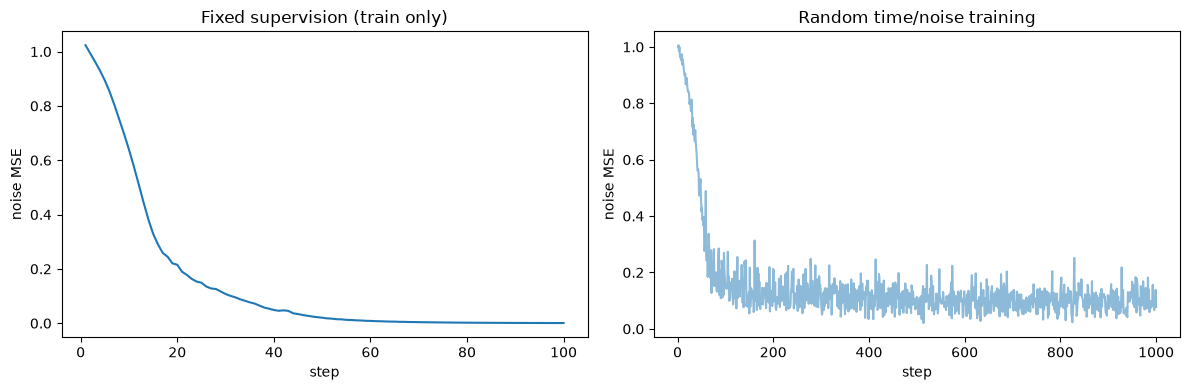

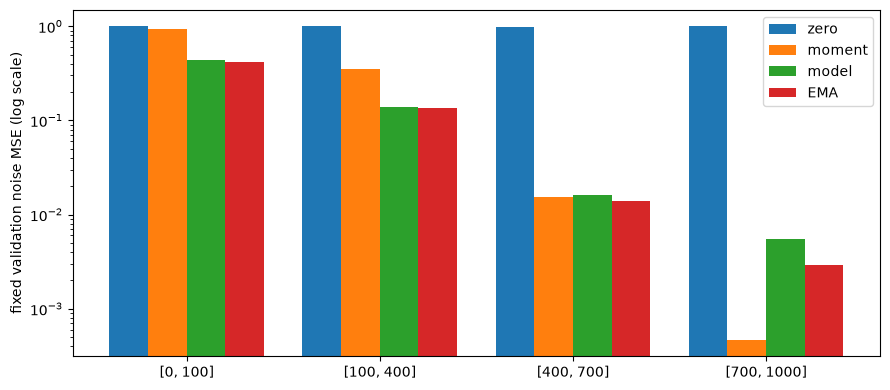

In [11]:
training_cfg = cfg["training"]
training_start = time.monotonic()
first_steps = training_cfg["max_steps"] // 2
segment_budget = min(training_cfg["max_seconds"] / 2, max(0.001, deadline - time.monotonic() - 300))
first_config = TrainConfig(
    str(RUN / "verified_v2/random_first"),
    max_steps=first_steps,
    max_seconds=segment_budget,
    learning_rate=training_cfg["learning_rate"],
    ema_decay=training_cfg["ema_decay"],
    seed=SEED,
    device=DEVICE,
    checkpoint_every=training_cfg["checkpoint_every"],
    scheduler_source="project_core",
    require_exact_resume=True,
)
first_result = train_latent_denoiser(
    model,
    scheduler,
    train_dataset.latents,
    first_config,
    data_identity=train_dataset.identity,
    model_identity=model_identity,
    batch_size=training_cfg["batch_size"],
    data_seed=SEED,
)
resumed_model = TeachingDiT(**architecture)
second_config = TrainConfig(
    str(RUN / "verified_v2/random_resumed"),
    max_steps=training_cfg["max_steps"],
    max_seconds=min(
        max(0.001, training_cfg["max_seconds"] - (time.monotonic() - training_start)),
        max(0.001, deadline - time.monotonic() - 300),
    ),
    learning_rate=training_cfg["learning_rate"],
    ema_decay=training_cfg["ema_decay"],
    seed=SEED,
    device=DEVICE,
    checkpoint_every=training_cfg["checkpoint_every"],
    scheduler_source="project_core",
    require_exact_resume=True,
)
random_result = train_latent_denoiser(
    resumed_model,
    scheduler,
    train_dataset.latents,
    second_config,
    data_identity=train_dataset.identity,
    model_identity=model_identity,
    batch_size=training_cfg["batch_size"],
    data_seed=SEED,
    resume_path=first_result["checkpoint"],
)
model = resumed_model
checkpoint = torch.load(random_result["checkpoint"], map_location="cpu", weights_only=True)
ema_model = TeachingDiT(**architecture).to(DEVICE)
ema_model.load_state_dict(checkpoint["ema"])
ema_model.eval()
probe_final = evaluate_probe(model, "final")
probe_ema = evaluate_probe(ema_model, "ema")
print(
    {
        "first_final_step": first_result["final_step"],
        "resume_start": random_result["start_step"],
        "final_step": random_result["final_step"],
        "training_seconds": time.monotonic() - training_start,
        "stop_reason": random_result["stop_reason"],
        "probe_final": probe_final,
        "probe_ema": probe_ema,
    }
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fixed_metrics = fixed_result["metrics"]
axes[0].plot([r["step"] for r in fixed_metrics], [r["loss"] for r in fixed_metrics])
axes[0].set(title="Fixed supervision (train only)", xlabel="step", ylabel="noise MSE")
random_metrics = first_result["metrics"] + random_result["metrics"]
axes[1].plot([r["step"] for r in random_metrics], [r["loss"] for r in random_metrics], alpha=0.5)
axes[1].set(title="Random time/noise training", xlabel="step", ylabel="noise MSE")
fig.tight_layout()
fig.savefig(FIG / "training_curves.png", dpi=140)
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for offset, label, values in [
    (-0.3, "zero", [r["zero_mse"] for r in probe_initial]),
    (-0.1, "moment", [r["moment_mse"] for r in probe_initial]),
    (0.1, "model", [r["model_mse"] for r in probe_final]),
    (0.3, "EMA", [r["model_mse"] for r in probe_ema]),
]:
    ax.bar(x + offset, values, width=0.2, label=label)
ax.set_xticks(x, [str(r["time_bin"]) for r in probe_initial])
ax.set_ylabel("fixed validation noise MSE (log scale)")
ax.set_yscale("log")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "validation_bins.png", dpi=140)
plt.show()

## **八、中断恢复是继续同一个实验**

### **1. 保存权重为什么还不够**

只恢复网络会丢失 Adam 的动量与二阶矩、EMA、噪声随机状态和数据顺序；即使初始 loss 接近，也不等价于继续原来的训练。本周包装层在现有训练器外保存实验契约，至少包括数据身份、模型来源/结构、完整扩散日程和训练模式。改了其中任何一个，就拒绝伪装成原实验恢复。

个人 DDPM 的 state_dict 包含系数表，但普通属性 num_steps、clip_denoised 不是完整的实验配置；同名 scheduler_source 也不代表相同 beta。必须独立比较完整身份。CPU 同数据流下可以测试逐位一致；MPS 上结果可能受设备实现影响，不把跨设备差异当成恢复算法的绝对错误。

本周正式执行一次“前半段 → 新模型实例 → 加载 Checkpoint → 后半段”。严格连续/恢复相等的对照放在独立 CPU 工程测试里；Notebook 的真实训练恢复证明工程路径实际走过，不能靠仅打印 resume=True 代替。

In [12]:
print(
    {
        "resume_mode": random_result["resume_mode"],
        "resume_start_step": random_result["start_step"],
        "saved_data_cursor": checkpoint["data_state"]["cursor"],
        "saved_epoch": checkpoint["data_state"]["epoch"],
        "checkpoint": random_result["checkpoint"],
        "scope": "actual resume; exact CPU equality tested separately",
    }
)

{'resume_mode': 'stateful_exact', 'resume_start_step': 500, 'saved_data_cursor': 6000, 'saved_epoch': 1, 'checkpoint': '/Users/lucius/projects/personal/MiniGen/artifacts/runs/s2_week4/verified_v2/random_resumed/latest.pt', 'scope': 'actual resume; exact CPU equality tested separately'}


## **九、采样：从完全未知的噪声走回潜变量**

### **1. 预测噪声、估计干净值、计算后验、再加随机项**

给定当前 $z_t$ 与模型预测，先估计干净潜变量：

$$\hat z_0=\frac{z_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(z_t,t)}{\sqrt{\bar\alpha_t}}$$

再把它代入条件高斯后验：

$$\mu_t=\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}\hat z_0+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}z_t,\qquad\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$$

当论文 $t>1$ 时，$z_{t-1}=\mu_t+\sqrt{\tilde\beta_t}\xi$，$\xi$ 是本步新抽的标准噪声；到 $t=1$（代码索引 0）只返回均值。本周复用你已实现并验收的 `DDPMScheduler.step`，不再新增一份反向公式实现。

**clip_denoised=False**：图像像素有 [-1,1] 约定，VAE 潜变量没有这个限制。第三周已测得潜变量有不少值超出 1；直接裁剪会改变已学分布并毁掉解码数值。

不要求每一步解码图都合理。远离干净数据的 $z_t$ 并非编码器输出分布，早期解码只是轨迹可视化。只有 completed=True、completed_steps=1000 才称最终采样完成；完成仍不保证图片质量合格。

In [13]:
sample_cfg = cfg["sampling"]
initial_noise = torch.randn(
    (sample_cfg["num_samples"], 4, 16, 16),
    generator=torch.Generator().manual_seed(sample_cfg["seed_initial"]),
).to(DEVICE)
# 降低 EMA 的早期滞后不会靠临时改衰减解决；本次固定使用 EMA 并保留原始参数探针。
sampling = sample_ddpm(
    ema_model,
    scheduler,
    initial_noise,
    seed=sample_cfg["seed_reverse"],
    max_seconds=min(sample_cfg["max_seconds"], max(0.001, deadline - time.monotonic())),
    capture=sample_cfg["capture"],
)
print({k: v for k, v in sampling.items() if k not in ["images", "snapshots"]})
print(
    {"latent_min": sampling["images"].min().item(), "latent_max": sampling["images"].max().item()}
)

{'completed': True, 'completed_steps': 1000, 'elapsed_seconds': 3.6614514170214534, 'seed': 42, 'model_calls': 1000}
{'latent_min': -23.834796905517578, 'latent_max': 14.579974174499512}


### **2. DDIM 选读：跳的是日程位置，不是随意少调用几次 step**

确定性 DDIM 在原训练日程中选取 $s<t$，用当前预测先得到 $\hat z_0$，再更新到所选更早时刻：

$$z_s=\sqrt{\bar\alpha_s}\hat z_0+\sqrt{1-\bar\alpha_s}\epsilon_\theta(z_t,t)$$

最后到干净数据边界时取 $\bar\alpha_0=1$（这里 0 是论文干净态，代码没有这个带噪索引）。这是 DDIM 随机系数为零时的更新，具有明确路径和时间定义；它不等于把 DDPM 的相邻一步更新拿来跨很多索引。

本次不实现或运行 DDIM，以免在完整链还没理解时混入第二套采样变量。读论文第 3–4 节时回答：训练目标为什么可以复用？确定性如何依赖初始噪声？少步的误差为什么仍要评测？

## **十、解码、诊断和真实失败**

### **1. 重建与生成分别展示**

重建有真实图作为参照，用来检查表示上限；生成从独立噪声开始，没有逐图的“正确答案”。本周模型不输入文本，因此不能给任意生成图附上验证描述，再计算条件准确率。

我们保留全部 8 张固定种子生成图，不删失败；报告规则解析出的对象数和失败比例，仅作为诊断。第三周解析器只针对规则图形，可能把纹理、碎块误认为形状，**可解析不等于高质量**，更不等于正式 S3 指标通过。

再找每张生成潜变量在训练缓存中的欧氏最近邻，并展示其原图。距离受潜空间尺度、背景和编码方式影响，只用于观察明显复用或模式退化；近邻相似不能直接证明记忆，距离大也不能保证没有记忆。

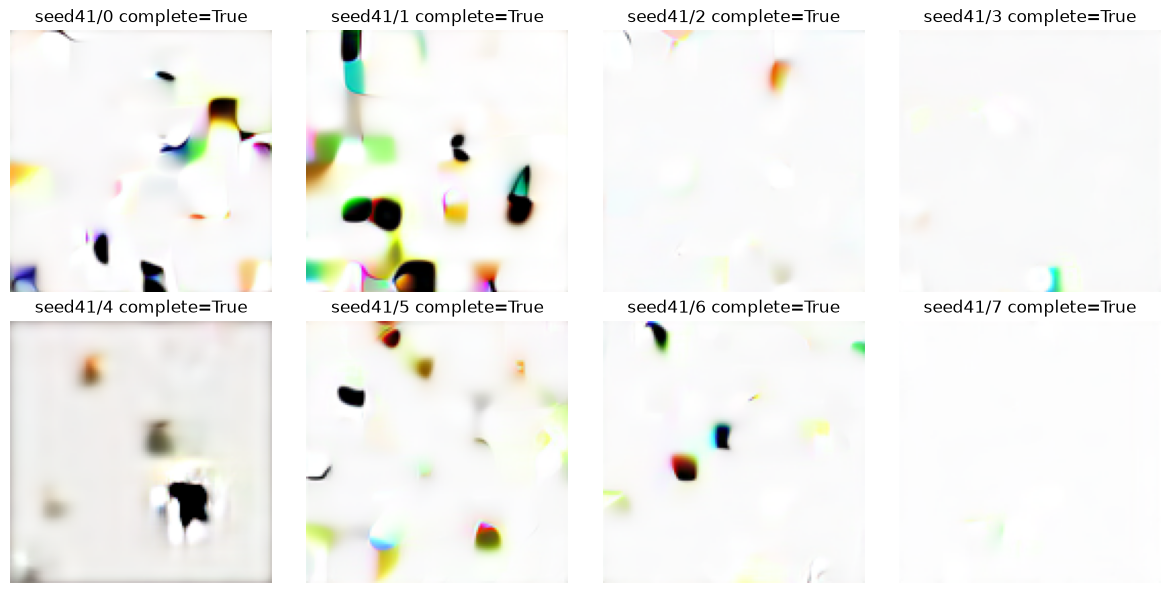

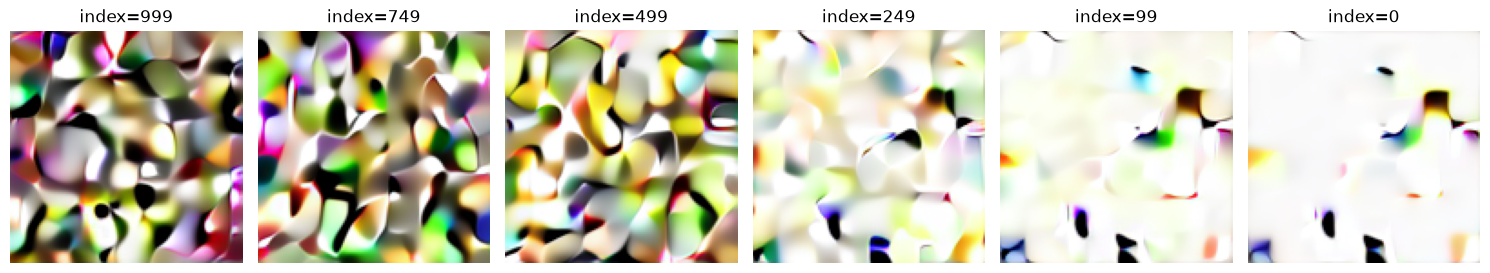

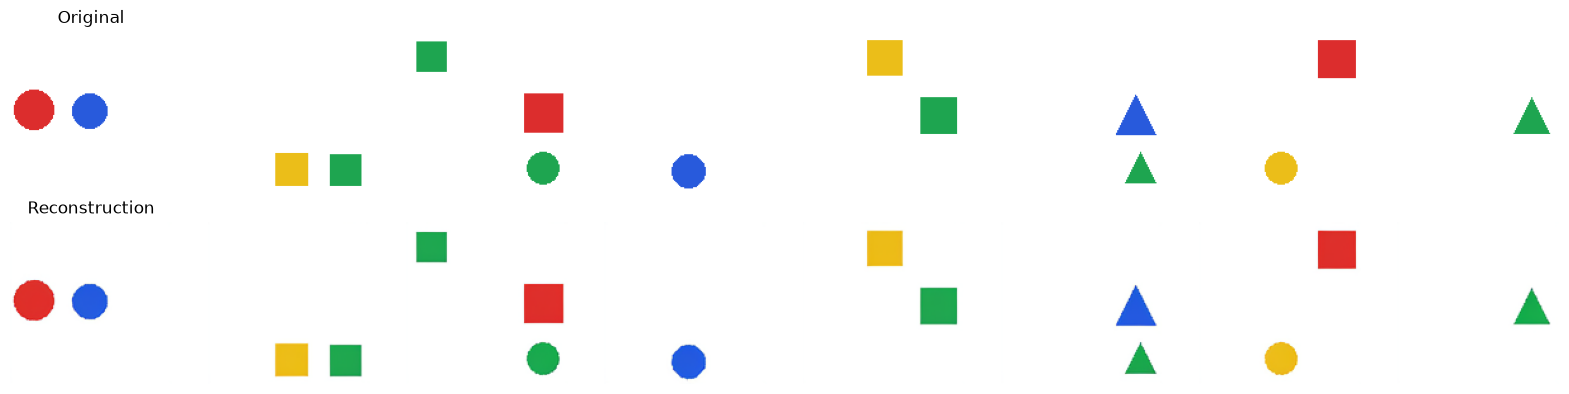

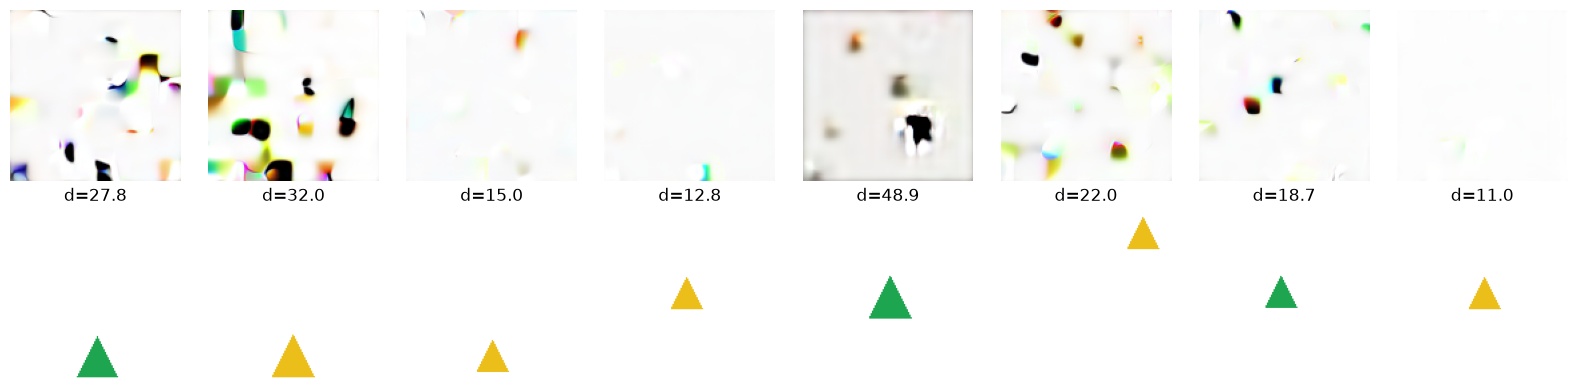

{'diagnostic_parse_failure_count': 6, 'images': 8, 'parsed_object_counts': [0, 1, 0, 0, 0, 1, 0, 0], 'conditional_accuracy': 'not_applicable', 'nearest_train_ids': ['synthetic_icons_week3_v1-train-00670', 'synthetic_icons_week3_v1-train-02291', 'synthetic_icons_week3_v1-train-06206', 'synthetic_icons_week3_v1-train-05339', 'synthetic_icons_week3_v1-train-01872', 'synthetic_icons_week3_v1-train-06572', 'synthetic_icons_week3_v1-train-05323', 'synthetic_icons_week3_v1-train-08492'], 'decode_and_diagnostics_seconds': 1.9352952089393511}


In [14]:
decode_start = time.monotonic()
generated_raw = adapter.decode(sampling["images"]).cpu()
generated_images = [to_image(x) for x in generated_raw]
# 全部固定种子样本展示；未完成链的输出只标记为中间态。
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, (ax, image) in enumerate(zip(axes.flat, generated_images, strict=True)):
    ax.imshow(image)
    ax.set_title(f"seed41/{i} complete={sampling['completed']}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "generated_all.png", dpi=140)
plt.show()
trajectory_indices = [999, 749, 499, 249, 99, 0]
available = [str(i) for i in trajectory_indices if str(i) in sampling["snapshots"]]
trajectory_images = adapter.decode(
    torch.cat([sampling["snapshots"][i][:1] for i in available])
).cpu()
fig, axes = plt.subplots(1, len(available), figsize=(15, 3), squeeze=False)
for ax, value, label in zip(axes.flat, trajectory_images, available, strict=True):
    ax.imshow(to_image(value))
    ax.set_title(f"index={label}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "reverse_trajectory.png", dpi=140)
plt.show()
reconstructed = adapter.decode(val_dataset.latents[:8]).cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    with Image.open(ROOT / "data" / val_rows[i]["image_path"]) as image:
        axes[0, i].imshow(image)
    axes[1, i].imshow(to_image(reconstructed[i]))
    for ax in axes[:, i]:
        ax.axis("off")
axes[0, 0].set_title("Original")
axes[1, 0].set_title("Reconstruction")
fig.tight_layout()
fig.savefig(FIG / "reconstruction_control.png", dpi=140)
plt.show()
parsed = [parse_icons(image) for image in generated_images]
parse_failures = sum(not objects or len(objects) > 3 for objects in parsed)
# 训练潜变量欧氏最近邻：不把这种距离称为感知质量或记忆检验的最终结论。
distances = torch.cdist(sampling["images"].flatten(1), train_dataset.latents.flatten(1))
nearest_distances, nearest_indices = distances.min(1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, index in enumerate(nearest_indices.tolist()):
    axes[0, i].imshow(generated_images[i])
    with Image.open(ROOT / "data" / train_rows[index]["image_path"]) as image:
        axes[1, i].imshow(image)
    for ax in axes[:, i]:
        ax.axis("off")
    axes[1, i].set_title(f"d={nearest_distances[i]:.1f}")
fig.tight_layout()
fig.savefig(FIG / "nearest_neighbors.png", dpi=140)
plt.show()
decode_seconds = time.monotonic() - decode_start
print(
    {
        "diagnostic_parse_failure_count": parse_failures,
        "images": len(parsed),
        "parsed_object_counts": [len(x) for x in parsed],
        "conditional_accuracy": "not_applicable",
        "nearest_train_ids": [train_rows[i]["sample_id"] for i in nearest_indices.tolist()],
        "decode_and_diagnostics_seconds": decode_seconds,
    }
)

### **2. 把损失、代价和样本一起看**

至少从三条线分析：①固定拟合是否成功但随机监督仍困难；②高噪声 MSE 是否很好而低噪声阶段不足；③解码图是否出现空白、颜色碎块、形状融合或对象数量退化。某张样本的失败不能仅凭观感归因于 VAE：先看同数据 VAE 重建，再看当前采样潜变量范围、噪声预测误差与训练预算。

耗时要分为缓存、训练、去噪链、解码；模型规模、batch、精度、设备和真实求值次数一起记录。这里是一个训练种子、一套短跑配方，不能用它判定 Transformer 优于 U-Net，也不能预判后续 Flow 更好。

若图像仍差，优先增加同配方的训练证据和分桶诊断；不能靠改种子筛图、临时裁剪潜变量或偷用预训练生成主干，把工程闭环变成看起来成功的演示。

In [15]:
results = {
    "date": "2026-10-30",
    "model_source": "notebook_reference",
    "reference_sha256": reference_sha,
    "scheduler_source": "project_core",
    "device": DEVICE,
    "precision": "float32",
    "seed": SEED,
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "configuration": cfg,
    "manifest_sha256": hash_file(manifest),
    "cache": {
        split: {k: v for k, v in report.items() if k != "identity"}
        for split, report in cache_reports.items()
    },
    "cache_seconds": cache_seconds,
    "prior_successful_execution_seconds": (
        json.loads((RUN / "first_successful_execution.json").read_text())["experiment_seconds"]
        if (RUN / "first_successful_execution.json").exists()
        else 0
    ),
    "model_parameters": sum(p.numel() for p in model.parameters()),
    "main_specification_parameters": main_spec_params,
    "main_specification_trained": False,
    "fixed_fit": {k: v for k, v in fixed_result.items() if k not in ["metrics", "contract"]},
    "random_training": {k: v for k, v in random_result.items() if k not in ["metrics", "contract"]},
    "resume": {
        "first_final_step": first_result["final_step"],
        "start_step": random_result["start_step"],
        "mode": random_result["resume_mode"],
        "continuous_equality_test": "see engineering verification",
    },
    "validation_probe": {"initial": probe_initial, "final": probe_final, "ema": probe_ema},
    "sampling": {k: v for k, v in sampling.items() if k not in ["images", "snapshots"]},
    "generated_latent_range": [sampling["images"].min().item(), sampling["images"].max().item()],
    "diagnostics": {
        "images": len(parsed),
        "parse_failures": parse_failures,
        "parsed_object_counts": [len(x) for x in parsed],
        "nearest_distances": nearest_distances.tolist(),
        "nearest_train_ids": [train_rows[i]["sample_id"] for i in nearest_indices.tolist()],
        "conditional_accuracy": None,
    },
    "decode_and_diagnostics_seconds": decode_seconds,
    "experiment_seconds": time.monotonic() - experiment_start,
    "personal_dit_verified": False,
    "personal_vae_verified": False,
    "understanding_verified": False,
    "cloud_cost_cny": 0,
    "test_set_used": False,
    "git_commit_performed": False,
    "limitations": [
        "single training seed and small teaching architecture",
        "no text condition or CFG",
        "rule parser is diagnostic only",
        "training loss is not generation quality",
        "full main architecture only checked for shape/parameter count",
    ],
}
results["total_successful_execution_seconds"] = (
    results["experiment_seconds"] + results["prior_successful_execution_seconds"]
)
(ROOT / "reports/stage2/week4_results.json").write_text(
    json.dumps(results, ensure_ascii=False, indent=2) + "\n"
)
print(
    json.dumps(
        {
            "full_train_cache": cache_reports["train"]["completed_count"],
            "full_validation_cache": cache_reports["validation"]["completed_count"],
            "random_final_step": random_result["final_step"],
            "sampling_complete": sampling["completed"],
            "experiment_seconds": results["experiment_seconds"],
            "source": "notebook_reference",
        },
        ensure_ascii=False,
        indent=2,
    )
)

{
  "full_train_cache": 10000,
  "full_validation_cache": 1000,
  "random_final_step": 1000,
  "sampling_complete": true,
  "experiment_seconds": 20.223982458002865,
  "source": "notebook_reference"
}


本次应重点阅读以下失败证据，而不是只看训练曲线：固定监督已经能充分拟合，但随机验证的难度分桶不相同。特别是在最高噪声桶，网络或 EMA 可能仍不如简单的高斯矩基线。此时把很小的噪声误差换算成干净潜变量，误差会被除以很小的累计信号而放大。它提示排查末端噪声预测偏差与训练预算，但不能凭这一项就断言全部生成错误都来自某一层。

短训还没有让模型可靠生成规范几何图标；零对象、碎块、属性与形状退化都要保留。VAE 重建对照保留基本对象，说明至少不能只把这些采样失败归因于解码器。如果继续实验，下一步应在相同数据、模型和种子下增加训练步数，检查预登记验证探针及全部固定样本，记录为延长训练的新实验；不要同时换架构、缩放、采样器和种子。

固定当前带噪输入时，噪声预测误差 $\Delta\epsilon$ 导致：

$$\Delta\hat z_0=-\sqrt{\frac{1-\bar\alpha_t}{\bar\alpha_t}}\Delta\epsilon$$

> 在本日程末端 $\bar\alpha_T\approx4.04\times10^{-5}$，放大系数约为157.41。单元素噪声偏差0.01会对应约1.574的干净值偏差。这是局部代数敏感度示例，不是整条链实际误差的预测，也不说明高噪声MSE较小就可以忽略。

## **十一、你应该能独立回答的自测**

### **1. 先合上代码，再检查参考解答**

1. 缓存固定均值之后，训练中还有哪两类主要随机性？
2. 一个 batch 的时间需要相同吗？训练为什么不用展开 1000 步？
3. 潜变量四通道均值不是 0，是不是应该立刻标准化？
4. 为什么零输出网络的初始 MSE 约为 1？为什么 MSE 很低仍可能只生成碎块？
5. 训练恢复只改变 beta_end，权重形状都对，能否叫继续同一实验？
6. 为什么不能直接把潜变量裁剪到 [-1,1]？
7. 8 张无条件样本能否用某 8 条描述算条件准确率？
8. 把 1000 步 DDPM 调用 20 次，与确定性 DDIM 有什么不同？

### **2. 参考解答与个人作业入口**

1. 扩散时间与高斯噪声仍每步变化，样本顺序也可独立打乱；VAE 后验噪声本周不抽样。
2. 每张图可独立抽时间；单步监督是目标期望的抽样估计，反向链是推理过程。
3. 先检查输入、权重和模型缩放约定。若要额外变换，必须明确新的可逆变换、训练版本与解码逆变换，再独立对照。
4. 标准噪声每元素方差为 1；容易的高噪声阶段能主导平均改进，而采样会累计预测误差，结构分布也未必学好。
5. 不能：带噪输入与反向路径变了；即使能载入权重，也属于新实验，包装层应拒绝恢复。
6. 潜变量不是像素，其值域不同；裁剪会抹掉解码器需要的信息。
7. 不能：模型未接收描述，没有对应的受控请求；本周只报告无条件分布与失败诊断。
8. DDPM 的 step 针对相邻时间；DDIM 使用选定时间对的更新公式，末端边界也需正确处理。

个人任务继续使用 [L03](../../learning/L03_DiT核心任务.md)，VAE 仍按 [L02](../../learning/L02_VAE核心任务.md) 完成。实现后运行独立验收，再把来源切换为个人模型；这份教学参考不会自动替你完成验收。

## **十二、本周计划、复现与下一步**

| 编号 | 主责 | 执行任务 | 验收与证据 |
| --- | --- | --- | --- |
| W4-01 | Agent | 数据、来源和表示门槛核验 | 固定数据和组件哈希、不使用测试集 |
| W4-02 | Agent | 全量训练/验证分片缓存 | 分片身份、哈希、完成标记和中断续建 |
| W4-03 | 你理解，Agent 组装教学 | 潜变量、DiT、DDPM 明确接入 | 来源、形状、参数量与个人边界 |
| W4-04 | Agent | 固定监督拟合 | 独立模型和固定图像/时间/噪声 |
| W4-05 | Agent，你解释 | 随机时间训练和分桶验证 | 未参与更新的探针、零与高斯矩基线 |
| W4-06 | Agent | 训练身份和恢复 | 连续对照、配置变更拒绝和跨进程恢复 |
| W4-07 | Agent，你分析 | 完整采样与失败诊断 | 全部固定图、1000次求值、最近邻 |
| W4-08 | Agent | 笔记、论文、检查与交接 | 真实报告和建议提交名；本轮不提交 |

工作目录为项目根目录，执行命令：

```bash
uv sync --locked --extra notebook --extra latent
uv run --locked --extra notebook --extra latent python scripts/execute_learning.py docs/learning/S2_第4周_潜空间扩散训练与采样.ipynb --html-output artifacts/runs/s2_week4/learning_preview.html
uv run --locked --extra notebook --extra latent pytest
uv run --locked python scripts/check_dit_core.py
```

重跑 Notebook 会显式进行本地缓存与短训；个人核心入口仍不调用教学参考。完整结果与限制见 [第四周报告](../../reports/stage2/week4.md)。下一周才研究文本、条件丢弃、CFG 和条件遵循，本周的无条件闭环不能提前满足这些要求。

建议 Git 提交名：`feat(s2): 添加第四周潜空间扩散训练与采样实验`。本轮不运行 git add、commit 或 push，待你完成第二周作业后自行整理提交。